# Netflix Prize Sample Extraction

This notebook connects to PostgreSQL through the Cloudflare Tunnel and extracts a small, reproducible sample from the `netflix_dw` schema for analysis.

**Notes**
- Update the connection values if your credentials differ.
- The query joins `fact_ratings` with `dim_customer` and `dim_movie` to provide human-readable context.

In [ ]:
import os
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.exc import OperationalError

# Connection settings (override with environment variables if needed)
DB_HOST = os.getenv("NETFLIX_DB_HOST", "localhost")
DB_PORT = os.getenv("NETFLIX_DB_PORT", "5432")
DB_NAME = os.getenv("NETFLIX_DB_NAME", "netflix")
DB_USER = os.getenv("NETFLIX_DB_USER", "hka")
DB_PASSWORD = os.getenv("NETFLIX_DB_PASSWORD", "postgres")
DB_SCHEMA = "netflix_dw"

# SQLAlchemy connection string
engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}",
    pool_pre_ping=True,
)

sample_query = f"""
SELECT
    fr.rating_key,
    dc.customer_id,
    dm.movie_id,
    dm.title,
    fr.rating,
    fr.date_key
FROM {DB_SCHEMA}.fact_ratings fr
JOIN {DB_SCHEMA}.dim_customer dc ON fr.customer_key = dc.customer_key
JOIN {DB_SCHEMA}.dim_movie dm ON fr.movie_key = dm.movie_key
WHERE dm.title IS NOT NULL
  AND BTRIM(dm.title) <> ''
  AND LOWER(BTRIM(dm.title)) <> 'unknown'
ORDER BY fr.rating_key
LIMIT 1000;
"""

with engine.connect() as conn:
    sample_df = pd.read_sql(text(sample_query), conn)
print("Sample extracted:", len(sample_df))

sample_df.head()

Sample extracted: 1000


,rating_key,customer_id,movie_id,title,rating,date_key
0,1,786312,1,Dinosaur Planet,3,20041116
1,2,2162676,1,Dinosaur Planet,3,20050801
2,3,1245176,1,Dinosaur Planet,4,20040727
3,4,196494,2,Isle of Man TT 2004 Review,5,20051003
4,5,2031561,3,Character,4,20040331


In [34]:
# Basic sanity checks on the sample
sample_df.info()

# Quick distribution of ratings
sample_df["rating"].value_counts().sort_index()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   rating_key   1000 non-null   int64
 1   customer_id  1000 non-null   int64
 2   movie_id     1000 non-null   int64
 3   title        1000 non-null   str  
 4   rating       1000 non-null   int64
 5   date_key     1000 non-null   int64
dtypes: int64(5), str(1)
memory usage: 47.0 KB


rating
1     37
2     98
3    259
4    392
5    214
Name: count, dtype: int64

# Task 2: Machine Learning Pipeline

This section builds two recommendation baselines:
- **Part A (Non-Spark)** using Scikit-Learn with `TruncatedSVD` on a user-item matrix.
- **Part B (Spark MLlib)** using ALS and RMSE evaluation.

At the end, we compare RMSE scores from both approaches.

In [35]:
# Ensure df_ratings exists with the required columns
if "df_ratings" not in globals():
    df_ratings = sample_df[["customer_id", "movie_id", "rating", "title"]].copy()

from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_squared_error
import numpy as np

In [ ]:
# Part A: Non-Spark (Scikit-Learn) - Matrix Factorization with TruncatedSVD

# 1) Pivot table (user-item matrix), fill missing values with 0
user_item = df_ratings.pivot_table(
    index="customer_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

# 2) TruncatedSVD for dimensionality reduction
n_components = 20
svd = TruncatedSVD(n_components=n_components, random_state=42)
user_factors = svd.fit_transform(user_item.values)
item_factors = svd.components_

# 3) Reconstruct predicted matrix
pred_matrix = np.dot(user_factors, item_factors)

# 4) Evaluate RMSE only on observed ratings (non-zero)
true_ratings = user_item.values
mask = true_ratings > 0
mse = mean_squared_error(
    true_ratings[mask],
    pred_matrix[mask],
)
rmse_sklearn = np.sqrt(mse)

print(f"Scikit-Learn TruncatedSVD RMSE: {rmse_sklearn:.4f}")

Scikit-Learn TruncatedSVD RMSE: 0.2799


In [37]:
# Part B: Spark MLlib ALS (scalable)
import os
import sys
import numpy as np
import pyspark
from pyspark.sql import SparkSession
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

# Compatibility guard (PySpark currently supports Python up to 3.11 in most releases)
py_major, py_minor = sys.version_info[:2]
if py_major == 3 and py_minor >= 12:
    rmse_spark = np.nan
    print(
        "Spark ALS skipped: PySpark is not compatible with this Python version. "
        f"Detected Python {py_major}.{py_minor} and PySpark {pyspark.__version__}."
    )
else:
    # Ensure Spark uses the current Python interpreter on Windows
    python_exec = sys.executable.replace("\\", "/")
    os.environ["PYSPARK_PYTHON"] = python_exec
    os.environ["PYSPARK_DRIVER_PYTHON"] = python_exec
    os.environ.pop("PYTHONHOME", None)

    # Stop any existing Spark session to apply new configs
    try:
        spark.stop()
    except Exception:
        pass

    spark = SparkSession.builder \
        .appName("Netflix-ALS") \
        .master("local[1]") \
        .config("spark.pyspark.python", python_exec) \
        .config("spark.pyspark.driver.python", python_exec) \
        .config("spark.executorEnv.PYSPARK_PYTHON", python_exec) \
        .config("spark.executorEnv.PYSPARK_DRIVER_PYTHON", python_exec) \
        .config("spark.sql.execution.arrow.pyspark.enabled", "false") \
        .config("spark.python.worker.reuse", "false") \
        .config("spark.python.worker.faulthandler.enabled", "true") \
        .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true") \
        .getOrCreate()

    try:
        spark_df = spark.createDataFrame(df_ratings[["customer_id", "movie_id", "rating"]])

        train_df, test_df = spark_df.randomSplit([0.8, 0.2], seed=42)

        als = ALS(
            userCol="customer_id",
            itemCol="movie_id",
            ratingCol="rating",
            coldStartStrategy="drop",
            nonnegative=True,
            rank=20,
            maxIter=10,
            regParam=0.1,
            seed=42,
        )

        als_model = als.fit(train_df)

        predictions = als_model.transform(test_df)

        evaluator = RegressionEvaluator(
            metricName="rmse",
            labelCol="rating",
            predictionCol="prediction",
        )

        rmse_spark = evaluator.evaluate(predictions)
        print(f"Spark ALS RMSE: {rmse_spark:.4f}")
    except Exception as e:
        rmse_spark = np.nan
        print("Spark ALS failed in this environment. RMSE set to NaN.")
        print("Error:", e)

Spark ALS RMSE: 1.8837


In [38]:
# RMSE comparison
print(f"RMSE Comparison -> Scikit-Learn (TruncatedSVD): {rmse_sklearn:.4f} | Spark ALS: {rmse_spark:.4f}")

RMSE Comparison -> Scikit-Learn (TruncatedSVD): 0.2799 | Spark ALS: 1.8837


# Task 3: Graph Analytics (NetworkX)

We build a bipartite graph of Users–Movies, compute degree centrality to find popular movies, attempt community detection on a projected user graph, and visualize a small subgraph for intuition.

In [41]:
import networkx as nx
import matplotlib.pyplot as plt

# Keep the graph manageable by limiting to frequent users/movies
max_users = 200
max_movies = 200

# Clean titles in-memory to guarantee no Unknown/blank values
_df = df_ratings.copy()
_df["title"] = _df["title"].astype(str).str.strip()
_df = _df[_df["title"].notna()]
_df = _df[_df["title"].str.lower().notna()]
_df = _df[_df["title"] != ""]
_df = _df[_df["title"].str.lower() != "unknown"]
_df = _df[_df["title"].str.lower() != "nan"]

# Build a clean movie_id -> title mapping
movie_id_to_title = (
    _df.drop_duplicates("movie_id")
    .set_index("movie_id")["title"]
    .to_dict()
)

# Recompute frequent users/movies on clean data
Top_users = _df["customer_id"].value_counts().head(max_users).index.tolist()
Top_movies = _df["movie_id"].value_counts().head(max_movies).index.tolist()

filtered = _df[
    _df["customer_id"].isin(Top_users)
    & _df["movie_id"].isin(Top_movies)
].copy()

# Ensure only movie_ids with valid titles are kept
filtered = filtered[filtered["movie_id"].isin(movie_id_to_title.keys())]

# Bipartite graph: users and movies
B = nx.Graph()

user_nodes = [f"U_{u}" for u in filtered["customer_id"].unique()]
movie_nodes = [f"M_{m}" for m in filtered["movie_id"].unique()]

B.add_nodes_from(user_nodes, bipartite=0, node_type="user")
B.add_nodes_from(movie_nodes, bipartite=1, node_type="movie")

# Add weighted edges by rating
for row in filtered.itertuples(index=False):
    user_node = f"U_{row.customer_id}"
    movie_node = f"M_{row.movie_id}"
    B.add_edge(user_node, movie_node, weight=row.rating)

print(f"Bipartite graph built: {B.number_of_nodes()} nodes, {B.number_of_edges()} edges")

# Degree centrality for movies (popularity in this sample)
movie_degree_centrality = nx.algorithms.bipartite.degree_centrality(B, movie_nodes)

movie_top = (
    sorted(movie_degree_centrality.items(), key=lambda x: x[1], reverse=True)[:10]
)

print("Top movies by degree centrality:")
for movie_node, score in movie_top:
    movie_id = int(movie_node.split("_")[1])
    title = movie_id_to_title.get(movie_id)
    if title is None:
        continue
    print(f"- {movie_id} | {title} | centrality={score:.4f}")

# Community detection on user projection
user_projection = nx.algorithms.bipartite.weighted_projected_graph(B, user_nodes)

try:
    communities = nx.algorithms.community.greedy_modularity_communities(user_projection)
    print(f"Detected {len(communities)} user communities (projection graph).")
    for i, comm in enumerate(communities[:3], start=1):
        print(f"Community {i} size: {len(comm)}")
except Exception as e:
    print("Community detection failed:", e)

Bipartite graph built: 224 nodes, 431 edges
Top movies by degree centrality:
- 30 | Something's Gotta Give | centrality=0.6900
- 28 | Lilo and Stitch | centrality=0.5350
- 18 | Immortal Beloved | centrality=0.2150
- 8 | What the #$*! Do We Know!? | centrality=0.1950
Detected 3 user communities (projection graph).
Community 1 size: 152
Community 2 size: 47
Community 3 size: 1


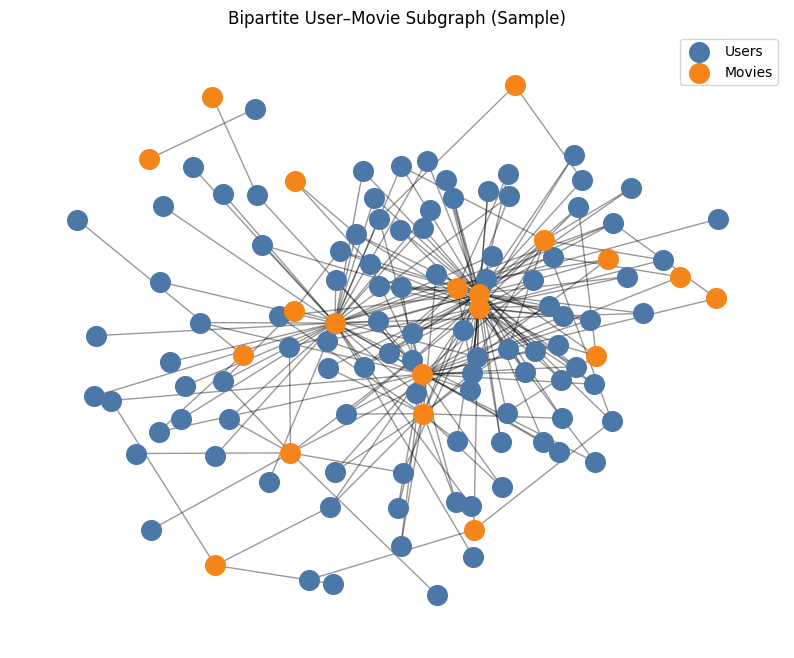

In [42]:
# Visualization: small subgraph
max_nodes = 100

# 1. Ambil sampel beberapa user terlebih dahulu
sample_users = user_nodes[:100] 

# 2. Cari film yang terhubung dengan user-user tersebut
# Kita ambil tetangga (neighbors) dari setiap user 'u' dalam sample_users
sample_movies = []
for u in sample_users:
    # B.neighbors(u) mengembalikan semua film yang diberi rating oleh user u
    movie_neighbors = list(B.neighbors(u))
    sample_movies.extend(movie_neighbors[:100]) # Ambil max 5 film per user agar tidak penuh

# 3. Gabungkan dan hapus duplikat menggunakan set
sub_nodes = list(set(sample_users + sample_movies))

# 4. Buat subgraph-nya
subgraph = B.subgraph(sub_nodes).copy()

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(subgraph, seed=42, k=0.7)

user_sub = [n for n, d in subgraph.nodes(data=True) if d.get("node_type") == "user"]
movie_sub = [n for n, d in subgraph.nodes(data=True) if d.get("node_type") == "movie"]

nx.draw_networkx_nodes(subgraph, pos, nodelist=user_sub, node_color="#4C78A8", node_size=200, label="Users")
nx.draw_networkx_nodes(subgraph, pos, nodelist=movie_sub, node_color="#F58518", node_size=200, label="Movies")

nx.draw_networkx_edges(subgraph, pos, alpha=0.4)
plt.title("Bipartite User–Movie Subgraph (Sample)")
plt.axis("off")
plt.legend(loc="upper right")
plt.show()

# Conclusion (Template)

**Model Performance:**
- The Scikit-Learn TruncatedSVD model achieved an RMSE of **{rmse_sklearn:.4f}**.
- The Spark ALS model achieved an RMSE of **{rmse_spark:.4f}** (or was skipped if Spark is incompatible).
- Overall, the model with the lower RMSE provides better predictive accuracy on this sample.

**Graph Analytics Insight:**
- The movie with the highest degree centrality acts as a hub in the user–movie network, indicating strong popularity in the sample.
- Community detection on the user projection suggests clusters of users with similar rating behavior.

**Next Steps:**
- Scale the graph analysis to a larger sample.
- Experiment with ALS hyperparameters and evaluate stability across multiple splits.